In [48]:
import pandas as pd
import numpy as np
import plotly.express as px

In [49]:
df = pd.read_csv("bitcoin_dataset.csv", index_col=0, parse_dates=True)
df.head()

,btc_market_price,btc_total_bitcoins,btc_market_cap,btc_trade_volume,btc_blocks_size,btc_avg_block_size,btc_n_orphaned_blocks,btc_n_transactions_per_block,btc_median_confirmation_time,btc_hash_rate,...,btc_cost_per_transaction_percent,btc_cost_per_transaction,btc_n_unique_addresses,btc_n_transactions,btc_n_transactions_total,btc_n_transactions_excluding_popular,btc_n_transactions_excluding_chains_longer_than_100,btc_output_volume,btc_estimated_transaction_volume,btc_estimated_transaction_volume_usd
Date,,,,,,,,,,,,,,,,,,,,,
2010-02-17,0.0,2043200.0,0.0,0.0,0.0,0.000235,0,1.0,0.0,0.000029,...,31.781022,0.0,241,244,41240,244,244,65173.13,36500.0,0.0
2010-02-18,0.0,2054650.0,0.0,0.0,0.0,0.000241,0,1.0,0.0,0.000029,...,154.463801,0.0,234,235,41475,235,235,18911.74,7413.0,0.0
2010-02-19,0.0,2063600.0,0.0,0.0,0.0,0.000228,0,1.0,0.0,0.000023,...,1278.516635,0.0,185,183,41658,183,183,9749.98,700.0,0.0
2010-02-20,0.0,2074700.0,0.0,0.0,0.0,0.000218,0,1.0,0.0,0.000028,...,22186.687990,0.0,224,224,41882,224,224,11150.03,50.0,0.0
2010-02-21,0.0,2085400.0,0.0,0.0,0.0,0.000234,0,1.0,0.0,0.000027,...,689.179876,0.0,218,218,42100,218,218,12266.83,1553.0,0.0


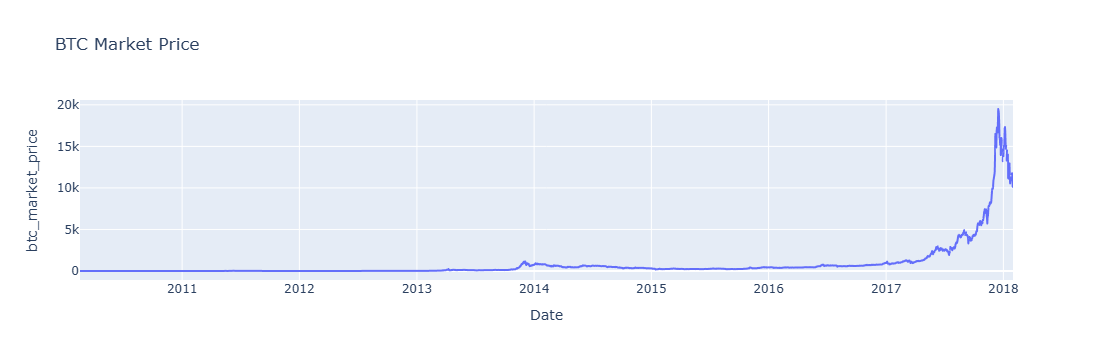

In [50]:
fig = px.line(df, x=df.index, y='btc_market_price', title='BTC Market Price')
fig.show()

In [51]:
df = px.data.stocks()
df

,date,GOOG,AAPL,AMZN,FB,NFLX,MSFT
0,2018-01-01,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,2018-01-08,1.018172,1.011943,1.061881,0.959968,1.053526,1.015988
2,2018-01-15,1.032008,1.019771,1.053240,0.970243,1.049860,1.020524
3,2018-01-22,1.066783,0.980057,1.140676,1.016858,1.307681,1.066561
4,2018-01-29,1.008773,0.917143,1.163374,1.018357,1.273537,1.040708
...,...,...,...,...,...,...,...
100,2019-12-02,1.216280,1.546914,1.425061,1.075997,1.463641,1.720717
101,2019-12-09,1.222821,1.572286,1.432660,1.038855,1.421496,1.752239
102,2019-12-16,1.224418,1.596800,1.453455,1.104094,1.604362,1.784896
103,2019-12-23,1.226504,1.656000,1.521226,1.113728,1.567170,1.802472


In [52]:
def up_bb(stock):
    return df[stock].rolling(window=5).mean() + 0.75*df[stock].rolling(window=5).mean().std()

def low_bb(stock):
    return df[stock].rolling(window=5).mean() - 0.75*df[stock].rolling(window=5).mean().std()

def mid_bb(stock):
    return df[stock].rolling(window=5).mean()

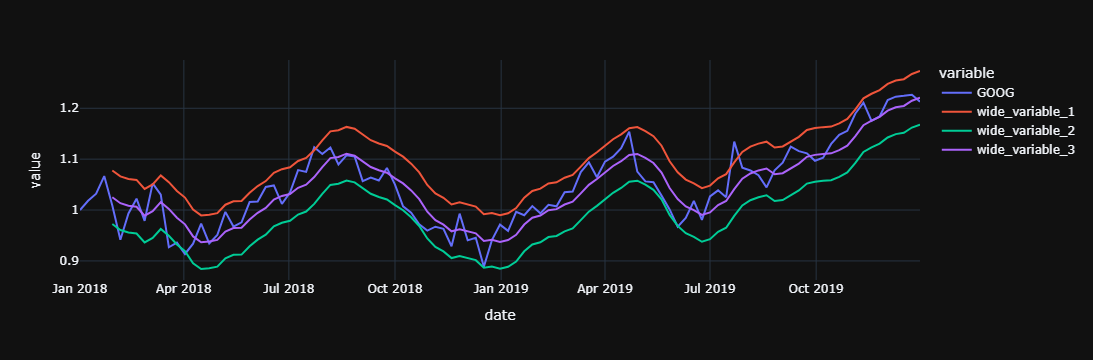

In [54]:
fig = px.line(df, x='date', y=['GOOG', up_bb('GOOG'), low_bb('GOOG'), mid_bb('GOOG')], template='plotly_dark')
fig.show()

In [55]:
from dash import Dash, dcc, html, Input, Output
import plotly.express as px

app = Dash(__name__)


app.layout = html.Div([
    html.H4('Analysis of the restaurant sales'),
    dcc.Graph(id="graph"),
    html.P("Names:"),
    dcc.Dropdown(id='names',
        options=['smoker', 'day', 'time', 'sex'],
        value='day', clearable=False
    ),
    html.P("Values:"),
    dcc.Dropdown(id='values',
        options=['total_bill', 'tip', 'size'],
        value='total_bill', clearable=False
    ),
])


@app.callback(
    Output("graph", "figure"),
    Input("names", "value"),
    Input("values", "value"))
def generate_chart(names, values):
    df = px.data.tips() # replace with your own data source
    fig = px.pie(df, values=values, names=names, hole=.3)
    return fig


app.run(debug=True)

ModuleNotFoundError: No module named 'dash'